# More efficient plants, less electricity?

Economic Analysis for Data Scientists, Assignment 2

**Author:** José Luis Fernández Huaita, Francesca Alexandra Panga, Xave Markey

## Setup

In [2]:
# 0.1 Packages and data
R.home()
library(tidyverse)
options(repr.plot.width = 10, repr.plot.height = 5)

energy <- read_csv("data/energy_firms.csv", show_col_types = FALSE)

group_colours  <- c(Control = "#52514e", Treated = "#2a78d6")
sector_colours <- c(Chemicals = "#eb6834", Textiles = "#1baf7a")

[1] "/Library/Frameworks/R.framework/Resources"

-- Attaching core tidyverse packages ------------------------ tidyverse 2.0.0 --
v dplyr     1.2.1     v readr     2.2.0
v forcats   1.0.1     v stringr   1.6.0
v ggplot2   4.0.3     v tibble    3.3.1
v lubridate 1.9.5     v tidyr     1.3.2
v purrr     1.2.2     
-- Conflicts ------------------------------------------ tidyverse_conflicts() --
x dplyr::filter() masks stats::filter()
x dplyr::lag()    masks stats::lag()
i Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors


In [3]:
# 0.2 Variables we construct
# - group: readable treatment label
# - window: the four periods we compare (pre-programme and three post windows)
# - *_base: each plant's average over the four pre-programme months (-3 to 0)
# - dlog_*: log change relative to the plant's own baseline (0.10 is roughly +10%)

energy <- energy |>
  mutate(
    group = factor(if_else(treated == 1, "Treated", "Control"), levels = c("Control", "Treated")),
    window = cut(month, breaks = c(-Inf, 0, 3, 7, Inf),
                 labels = c("Pre (-3 to 0)", "Months 1-3", "Months 4-7", "Months 8-12"))
  )

baseline <- energy |>
  filter(month <= 0) |>
  group_by(firm_id) |>
  summarise(across(c(output, labor, electricity), \(x) mean(x), .names = "{.col}_base"))

energy <- energy |>
  left_join(baseline, by = "firm_id") |>
  mutate(
    dlog_E = log(electricity / electricity_base),
    dlog_L = log(labor / labor_base),
    dlog_Q = log(output / output_base)
  )

# One row per plant: fixed characteristics and baseline (pre-programme) means
plants <- energy |>
  filter(month <= 0) |>
  group_by(firm_id, sector, treated, group, adjust_month) |>
  summarise(across(c(output, labor, electricity, output_price, wage, energy_price), \(x) mean(x)),
            .groups = "drop") |>
  mutate(energy_cost_share = energy_price * electricity /
           (wage * labor + energy_price * electricity))

In [4]:
# 0.3 Helper function: balance table
# Compares treated and control plants variable by variable, in levels and in logs
# (the variables are very skewed, so the log comparison is more informative).
# p-values come from Welch t-tests with one observation per plant.

balance_table <- function(data, variables) {
  map_dfr(variables, function(v) {
    control <- data[[v]][data$treated == 0]
    treated <- data[[v]][data$treated == 1]
    tibble(
      variable     = v,
      n_control    = length(control),
      mean_control = mean(control),
      n_treated    = length(treated),
      mean_treated = mean(treated),
      difference   = mean(treated) - mean(control),
      p_value      = t.test(treated, control)$p.value,
      diff_logs    = mean(log(treated)) - mean(log(control)),
      p_value_logs = t.test(log(treated), log(control))$p.value
    )
  }) |>
    mutate(across(where(is.double), \(x) round(x, 3)))
}

# Part 1: Explore electricity use before and after consulting

## 1. Explore and check the data.

Present evidence about these plants’ electricity consumption before and after the programme begins. You might examine averages, distributions, individual trajectories or changes relative to each plant’s baseline. There is no single correct presentation: choose the comparisons and visualisations you find informative, and explain what they reveal.

As part of your exploration, check the sample, panel structure, units and treatment assignment. Note any data issues or important differences across plants. You do not need to propose an economic explanation yet.

**TLDR of Section 1**

* **The data are clean and the design is as described.** 480 plants × 16 months, no missing values or duplicates, 40 treated and 40 control plants in every sector × staffing-review cohort. Prices are constant within each plant, and labour does not move while it is contractually fixed.
* **Treated plants are slightly larger at baseline, by chance.** Labour and output are 6–8% higher (p < 0.05 in logs), although the groups are jointly balanced. We therefore measure every outcome relative to each plant's own baseline.
* **Plants are very different from one another.** Baseline electricity ranges from about 1,300 to 17,500 MWh a month and electricity prices vary 40-fold, so we work with proportional changes and report totals separately.
* **Electricity first falls, then rises above its starting level.** Treated plants use about 26% less electricity in months 1–3, about 10% less in months 4–7 and about 9% *more* in months 8–12. Control plants do not change.
* **A single "after" average would hide this.** Averaged over months 1–12, the changes largely cancel out.

### 1.1 Data audit

As in any randomised evaluation, we first check that the data support the comparison we want to make:
* Balanced panel and clean data
* Treatment assigned as described, with comparable groups at baseline
* Programme rules implemented as described (constant prices, labour fixed until the review month)
* No common shocks affecting all plants
* Size of the recording errors

##### 1.1.1 Balanced panel and clean data
Every plant is observed in all 16 months (−3 to 12): 4 months before the programme and 12 after. There are no missing values or duplicated plant-months.

In [5]:
tibble(
  rows = nrow(energy),
  plants = n_distinct(energy$firm_id),
  months = n_distinct(energy$month),
  missing_values = sum(is.na(energy)),
  duplicated_plant_months = sum(duplicated(energy[c("firm_id", "month")]))
)

# Number of months observed per plant
energy |> count(firm_id, name = "months_observed") |> count(months_observed, name = "plants")

rows,plants,months,missing_values,duplicated_plant_months
<int>,<int>,<int>,<int>,<int>
7680,480,16,0,0


months_observed,plants
<int>,<int>
16,480


##### 1.1.2 Treatment assignment and baseline balance
Assignment was randomised within each sector and staffing-review cohort. Each of the six cells has exactly 40 treated and 40 control plants.

At baseline, prices are very similar across groups. Treated plants are somewhat larger: labour is about 8% higher and output about 6% higher (p ≈ 0.01–0.03 in logs), and electricity about 7% higher (p ≈ 0.06). A joint test does not reject balance (p ≈ 0.28), so this looks like chance imbalance rather than a problem with the randomisation. It still matters for how we measure effects: comparing post-programme **levels** would mix the programme with these baseline differences. We therefore compare each plant with its own baseline (and, in Question 3, treated with control changes).

In [6]:
# Plants per sector, staffing-review cohort and group
plants |>
  count(sector, adjust_month, group) |>
  pivot_wider(names_from = group, values_from = n)

# Baseline balance, one observation per plant (average of months -3 to 0)
plants |>
  balance_table(c("electricity", "labor", "output", "output_price", "wage", "energy_price"))

# Joint test: do baseline characteristics predict treatment? (F-test p-value)
joint <- lm(treated ~ log(electricity) + log(labor) + log(output) +
              log(output_price) + log(wage) + log(energy_price), data = plants)
f <- summary(joint)$fstatistic
tibble(F_statistic = round(f[["value"]], 2),
       p_value = round(pf(f[["value"]], f[["numdf"]], f[["dendf"]], lower.tail = FALSE), 3))

sector,adjust_month,Control,Treated
<chr>,<dbl>,<int>,<int>
Chemicals,4,40,40
Chemicals,6,40,40
Chemicals,8,40,40
Textiles,4,40,40
Textiles,6,40,40
Textiles,8,40,40


variable,n_control,mean_control,n_treated,mean_treated,difference,p_value,diff_logs,p_value_logs
<chr>,<int>,<dbl>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
electricity,240,4108.708,240,4413.708,305.000,0.103,0.076,0.059
labor,240,161.888,240,174.581,12.693,0.042,0.087,0.013
output,240,76.595,240,80.871,4.276,0.053,0.060,0.032
output_price,240,22714.275,240,23341.821,627.545,0.594,0.013,0.785
wage,240,1415.703,240,1404.892,-10.811,0.498,-0.007,0.527
energy_price,240,163.687,240,162.973,-0.714,0.945,-0.013,0.840


F_statistic,p_value
<dbl>,<dbl>
1.25,0.278


##### 1.1.3 Programme rules implemented as described
* Sector, treatment, review month and all three prices are constant within every plant.
* `labor_adjustable` follows the institutional rule exactly: labour is adjustable before month 1 and from the review month onwards.
* While labour is fixed, it stays at its baseline level in both groups. The month-to-month variation (about 1.6%) is the size of the recording noise.

In [7]:
# Plants in which each characteristic takes more than one value (should be 0)
energy |>
  group_by(firm_id) |>
  summarise(across(c(sector, treated, adjust_month, output_price, wage, energy_price), n_distinct)) |>
  summarise(across(-firm_id, \(x) sum(x > 1)))

# labor_adjustable should equal 1 before month 1 and from the review month on
energy |>
  mutate(rule = as.integer(month <= 0 | month >= adjust_month)) |>
  summarise(rows = n(), rows_matching_rule = sum(rule == labor_adjustable))

# Labour relative to baseline while it is fixed
energy |>
  filter(labor_adjustable == 0) |>
  group_by(group) |>
  summarise(plant_months = n(),
            mean_dlog_L = round(mean(dlog_L), 4),
            sd_dlog_L = round(sd(dlog_L), 4))

sector,treated,adjust_month,output_price,wage,energy_price
<int>,<int>,<int>,<int>,<int>,<int>
0,0,0,0,0,0


rows,rows_matching_rule
<int>,<int>
7680,7680


group,plant_months,mean_dlog_L,sd_dlog_L
<fct>,<int>,<dbl>,<dbl>
Control,1200,3e-04,0.0163
Treated,1200,0e+00,0.0159


##### 1.1.4 Size of the recording errors
Within each plant, quantities vary by only 1–2% across the four baseline months, when nothing should change. This is the recording noise mentioned in the brief. It is small relative to the changes we study, but it is a reason to average several months rather than rely on a single one.

In [8]:
# Mean within-plant coefficient of variation over months -3 to 0 (%)
energy |>
  filter(month <= 0) |>
  group_by(firm_id) |>
  summarise(across(c(output, labor, electricity), \(x) sd(x) / mean(x))) |>
  summarise(across(-firm_id, \(x) round(100 * mean(x), 2)))

output,labor,electricity
<dbl>,<dbl>,<dbl>
1.65,1.27,1.84


### 1.2 Differences across plants

**Units.** Output is in standardised batches, labour in blocks of 100 paid worker-hours and electricity in MWh, all monthly totals; prices are in CU per batch, per labour block and per MWh.

We can make the following observations:
* **Size.** Baseline electricity ranges from about 1,300 to 17,500 MWh a month (median about 3,800). The largest 10% of plants use about 21% of all electricity, so totals are weighted towards large plants.
* **Prices.** Wages are similar across sectors (about 1,400 CU per block). Electricity is more expensive and more dispersed in Chemicals (mean 186 vs 140 CU/MWh), with a range of roughly 20 to 835 CU/MWh.
* **Output and electricity prices move together.** Across plants, output and electricity prices are strongly correlated (0.77 in logs). Output price and electricity use are only weakly related (0.29), because plants also differ in productivity and size; this is a cross-plant correlation, not a causal relationship.
* **Electricity is the main variable cost.** On average it accounts for about 68% of the cost of labour plus electricity (72% in Chemicals, 65% in Textiles), ranging from about 31% to 89%. Plants for which electricity matters more may respond differently to the programme.

In [9]:
# Summary by sector, one observation per plant
plants |>
  pivot_longer(c(electricity, labor, output, output_price, wage, energy_price, energy_cost_share),
               names_to = "variable") |>
  group_by(variable, sector) |>
  summarise(mean = mean(value), median = median(value), min = min(value), max = max(value),
            .groups = "drop") |>
  mutate(across(where(is.double), \(x) signif(x, 4)))

# Share of total baseline electricity used by the largest 10% of plants
plants |>
  arrange(desc(electricity)) |>
  summarise(top_10pct_share = round(sum(head(electricity, round(0.1 * n()))) / sum(electricity), 3))

variable,sector,mean,median,min,max
<chr>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>
electricity,Chemicals,4.196e+03,3.756e+03,1258.0000,1.319e+04
electricity,Textiles,4.327e+03,3.747e+03,1414.0000,1.753e+04
energy_cost_share,Chemicals,7.156e-01,7.302e-01,0.3988,8.914e-01
energy_cost_share,Textiles,6.512e-01,6.702e-01,0.3099,8.890e-01
energy_price,Chemicals,1.863e+02,1.527e+02,33.0000,8.349e+02
energy_price,Textiles,1.403e+02,1.194e+02,20.9100,5.962e+02
labor,Chemicals,1.664e+02,1.525e+02,61.8900,3.748e+02
labor,Textiles,1.700e+02,1.535e+02,58.4200,5.518e+02
output,Chemicals,7.893e+01,7.677e+01,33.5500,1.937e+02


top_10pct_share
<dbl>
0.206


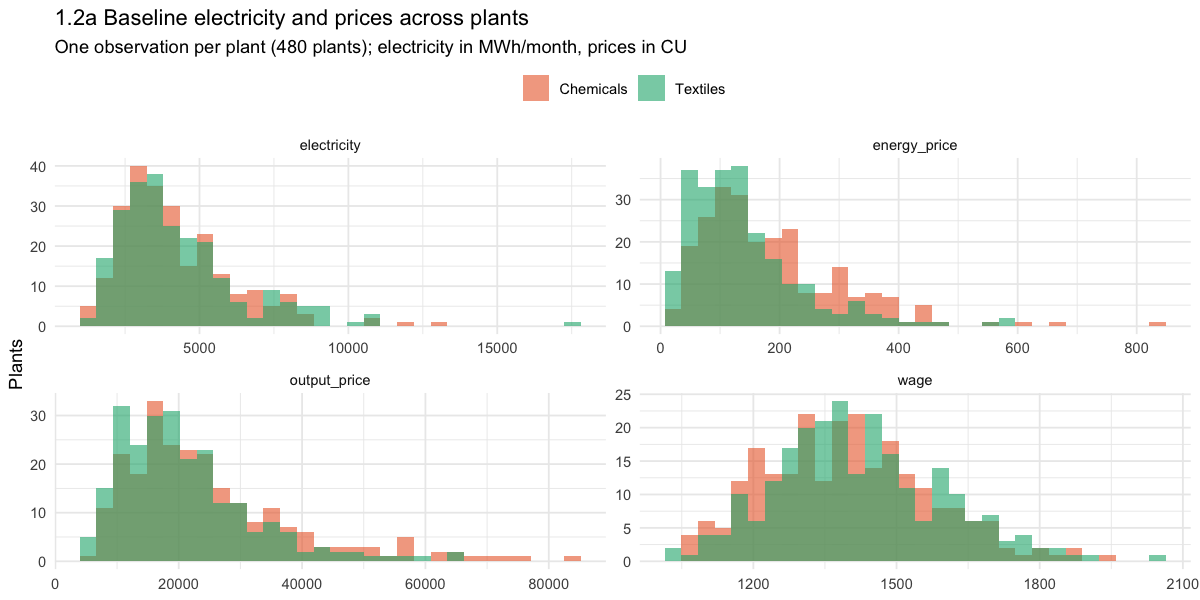

In [10]:
# Distribution of prices and baseline electricity, by sector
plants |>
  pivot_longer(c(electricity, wage, energy_price, output_price), names_to = "variable") |>
  ggplot(aes(x = value, fill = sector)) +
  geom_histogram(bins = 30, alpha = 0.6, position = "identity") +
  facet_wrap(~variable, scales = "free") +
  scale_fill_manual(values = sector_colours, name = NULL) +
  labs(title = "1.2a Baseline electricity and prices across plants",
       subtitle = "One observation per plant (480 plants); electricity in MWh/month, prices in CU",
       x = NULL, y = "Plants") +
  theme_minimal() +
  theme(legend.position = "top")

cor_logs_output_price_energy_price,cor_logs_output_price_electricity
<dbl>,<dbl>
0.77,0.29


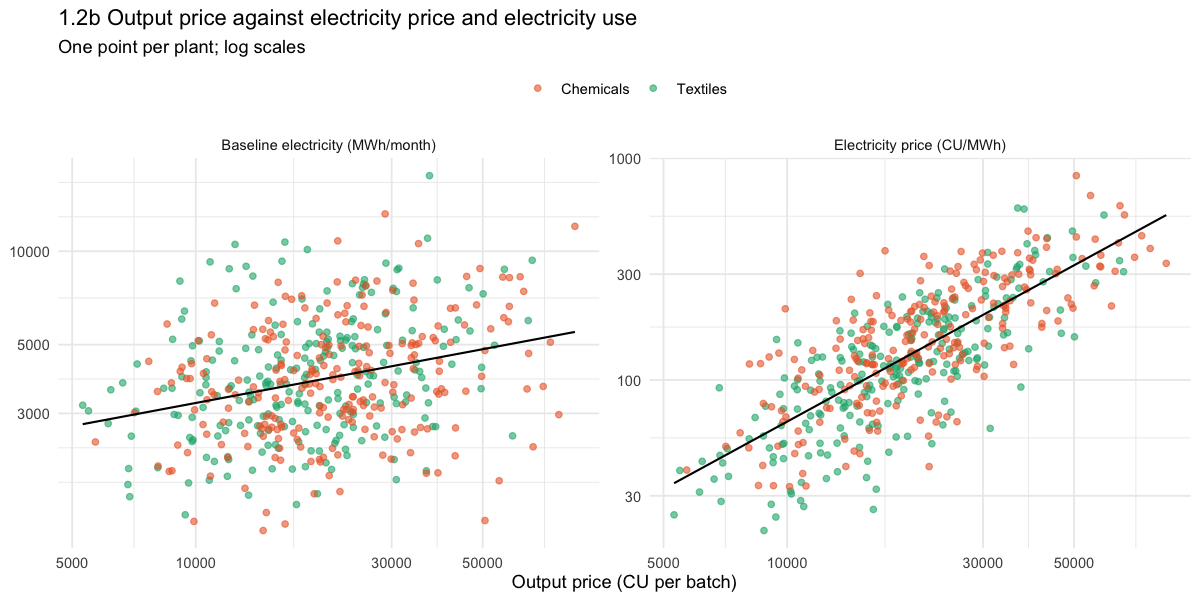

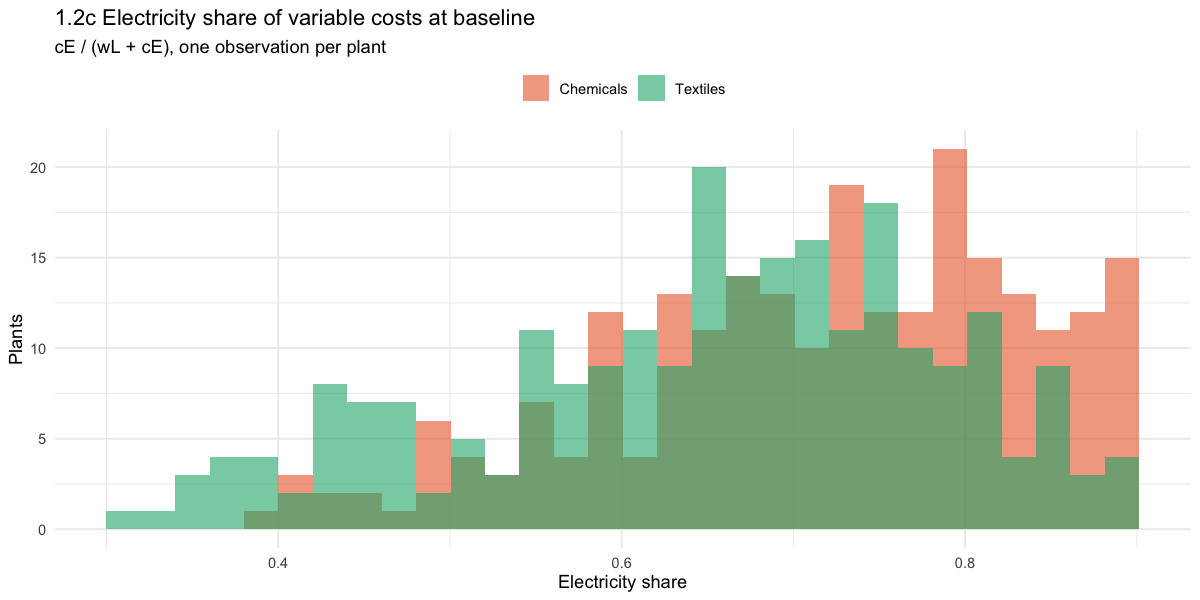

In [11]:
# Output price against electricity price and against baseline electricity (log scales)
plants |>
  summarise(cor_logs_output_price_energy_price = round(cor(log(output_price), log(energy_price)), 2),
            cor_logs_output_price_electricity  = round(cor(log(output_price), log(electricity)), 2))

plants |>
  pivot_longer(c(energy_price, electricity), names_to = "variable") |>
  mutate(variable = recode(variable, energy_price = "Electricity price (CU/MWh)",
                           electricity = "Baseline electricity (MWh/month)")) |>
  ggplot(aes(x = output_price, y = value, colour = sector)) +
  geom_point(alpha = 0.6) +
  geom_smooth(method = "lm", se = FALSE, colour = "black", linewidth = 0.6, formula = y ~ x) +
  scale_x_log10() + scale_y_log10() +
  facet_wrap(~variable, scales = "free_y") +
  scale_colour_manual(values = sector_colours, name = NULL) +
  labs(title = "1.2b Output price against electricity price and electricity use",
       subtitle = "One point per plant; log scales",
       x = "Output price (CU per batch)", y = NULL) +
  theme_minimal() +
  theme(legend.position = "top")

# Share of electricity in the cost of labour plus electricity
plants |>
  ggplot(aes(x = energy_cost_share, fill = sector)) +
  geom_histogram(bins = 30, alpha = 0.6, position = "identity") +
  scale_fill_manual(values = sector_colours, name = NULL) +
  labs(title = "1.2c Electricity share of variable costs at baseline",
       subtitle = "cE / (wL + cE), one observation per plant",
       x = "Electricity share", y = "Plants") +
  theme_minimal() +
  theme(legend.position = "top")

### 1.3 Electricity before and after the programme starts

Because plants differ so much in size, we measure each plant's electricity relative to its own baseline (log change, roughly a percentage change). We also report total MWh, which is what matters for aggregate consumption.

We can make the following observations:
* **Control plants are flat** throughout the 16 months, so there is no common shock affecting all plants.
* **Treated plants fall sharply and immediately.** In months 1–3, electricity is about 26% below baseline, and every treated plant uses less than before.
* **The saving then erodes in steps.** In months 4–7 the average gap is about −10%, but the spread across plants is very wide. By months 8–12, treated plants use about 9% *more* electricity than at baseline, and 83% of them are above their own baseline.
* **Totals tell the same story.** Total electricity of treated plants is 26% lower in months 1–3, 7% lower in months 4–7 and 10% higher in months 8–12. The total changes differ slightly from the average plant's change because larger plants weigh more in the total.
* **Plants differ in how far they rebound.** By months 8–12, about one in six treated plants is still below baseline.

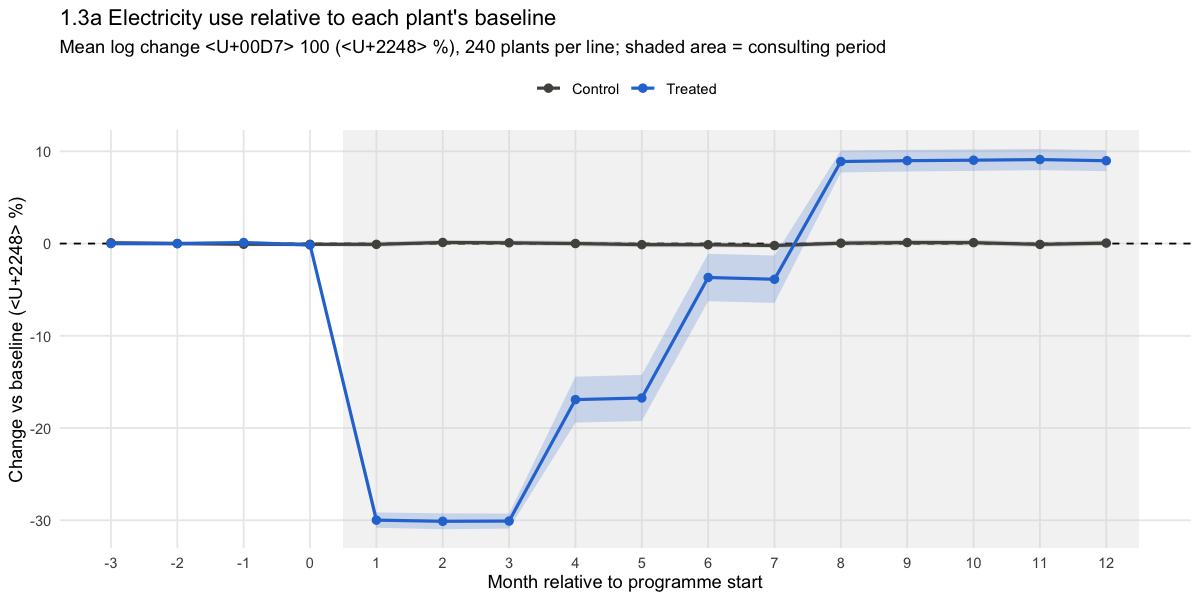

In [12]:
# Mean change relative to own baseline, by month and group, with 95% intervals across plants
energy |>
  group_by(month, group) |>
  summarise(mean = mean(dlog_E), se = sd(dlog_E) / sqrt(n()), .groups = "drop") |>
  ggplot(aes(x = month, y = 100 * mean, colour = group)) +
  annotate("rect", xmin = 0.5, xmax = 12.5, ymin = -Inf, ymax = Inf, fill = "grey85", alpha = 0.3) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_ribbon(aes(ymin = 100 * (mean - 1.96 * se), ymax = 100 * (mean + 1.96 * se), fill = group),
              alpha = 0.2, colour = NA) +
  geom_line(linewidth = 0.9) +
  geom_point(size = 2) +
  scale_colour_manual(values = group_colours, name = NULL) +
  scale_fill_manual(values = group_colours, guide = "none") +
  scale_x_continuous(breaks = -3:12) +
  labs(title = "1.3a Electricity use relative to each plant's baseline",
       subtitle = "Mean log change × 100 (≈ %), 240 plants per line; shaded area = consulting period",
       x = "Month relative to programme start", y = "Change vs baseline (≈ %)") +
  theme_minimal() +
  theme(legend.position = "top", panel.grid.minor = element_blank())

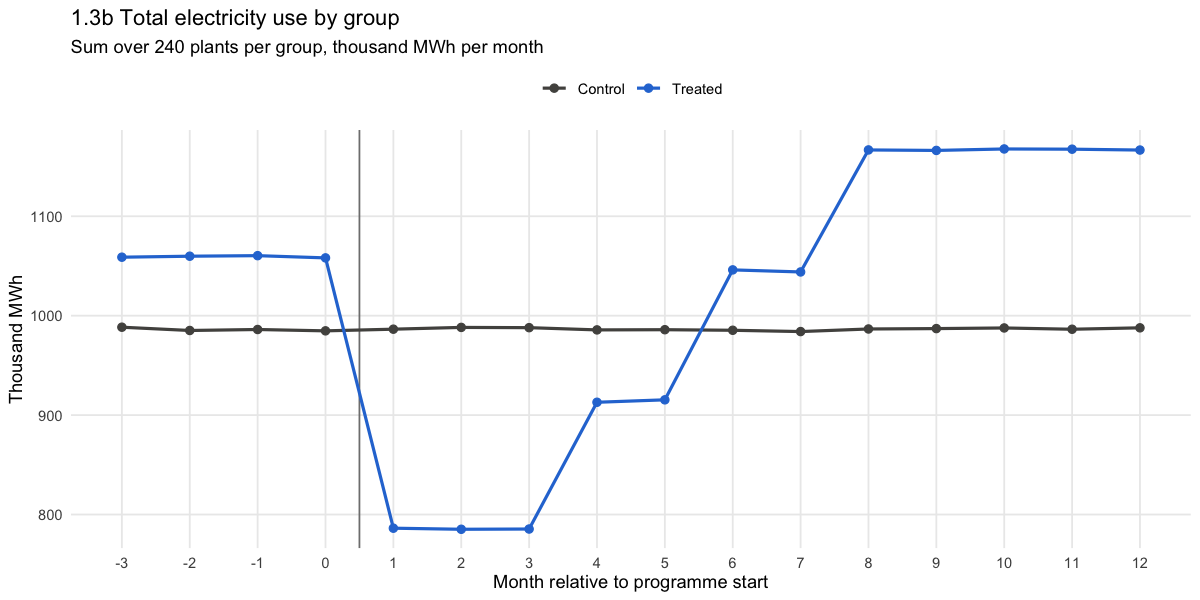

In [13]:
# Total electricity by month and group (thousand MWh)
energy |>
  group_by(month, group) |>
  summarise(total = sum(electricity) / 1000, .groups = "drop") |>
  ggplot(aes(x = month, y = total, colour = group)) +
  geom_vline(xintercept = 0.5, colour = "grey50") +
  geom_line(linewidth = 0.9) +
  geom_point(size = 2) +
  scale_colour_manual(values = group_colours, name = NULL) +
  scale_x_continuous(breaks = -3:12) +
  labs(title = "1.3b Total electricity use by group",
       subtitle = "Sum over 240 plants per group, thousand MWh per month",
       x = "Month relative to programme start", y = "Thousand MWh") +
  theme_minimal() +
  theme(legend.position = "top", panel.grid.minor = element_blank())

In [14]:
# Summary by window: average plant's change and change in total electricity
plant_windows <- energy |>
  group_by(firm_id, group, window) |>
  summarise(electricity = mean(electricity), dlog_E = mean(dlog_E), .groups = "drop")

plant_windows |>
  group_by(group, window) |>
  summarise(
    plants = n(),
    mean_change_pct = 100 * (exp(mean(dlog_E)) - 1),
    sd_change_log_points = 100 * sd(dlog_E),
    share_above_baseline = if_else(window[1] == "Pre (-3 to 0)", NA_real_, mean(dlog_E > 0)),
    total_MWh_per_month = sum(electricity),
    .groups = "drop"
  ) |>
  group_by(group) |>
  mutate(total_change_pct = 100 * (total_MWh_per_month / total_MWh_per_month[window == "Pre (-3 to 0)"] - 1)) |>
  ungroup() |>
  mutate(across(where(is.double), \(x) round(x, 2)))

group,window,plants,mean_change_pct,sd_change_log_points,share_above_baseline,total_MWh_per_month,total_change_pct
<fct>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Control,Pre (-3 to 0),240,-0.02,0.01,NA,986089.9,0.00
Control,Months 1-3,240,0.04,1.49,0.52,987523.9,0.15
Control,Months 4-7,240,-0.11,1.31,0.48,985236.5,-0.09
Control,Months 8-12,240,0.04,1.33,0.53,987085.6,0.10
Treated,Pre (-3 to 0),240,-0.01,0.01,NA,1059290.0,0.00
Treated,Months 1-3,240,-25.96,6.44,0.00,785605.8,-25.84
Treated,Months 4-7,240,-9.79,17.41,0.28,979578.5,-7.52
Treated,Months 8-12,240,9.42,9.00,0.83,1166941.7,10.16


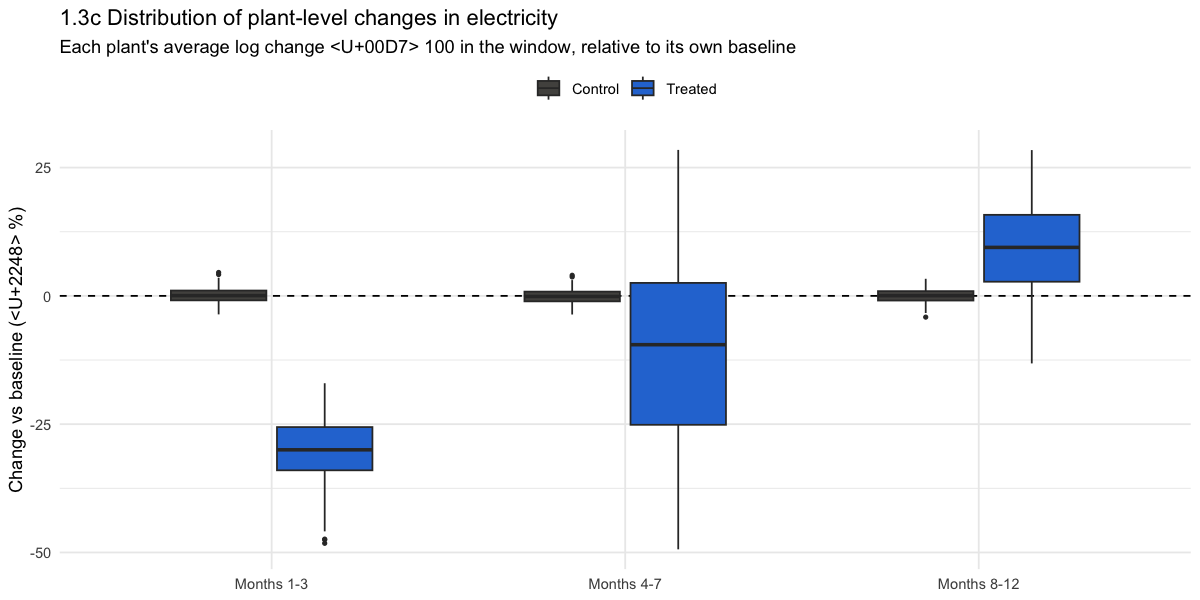

In [15]:
# Distribution of plant-level changes in each post-programme window
plant_windows |>
  filter(window != "Pre (-3 to 0)") |>
  ggplot(aes(x = window, y = 100 * dlog_E, fill = group)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_boxplot(outlier.size = 0.8, width = 0.6) +
  scale_fill_manual(values = group_colours, name = NULL) +
  labs(title = "1.3c Distribution of plant-level changes in electricity",
       subtitle = "Each plant's average log change × 100 in the window, relative to its own baseline",
       x = NULL, y = "Change vs baseline (≈ %)") +
  theme_minimal() +
  theme(legend.position = "top")

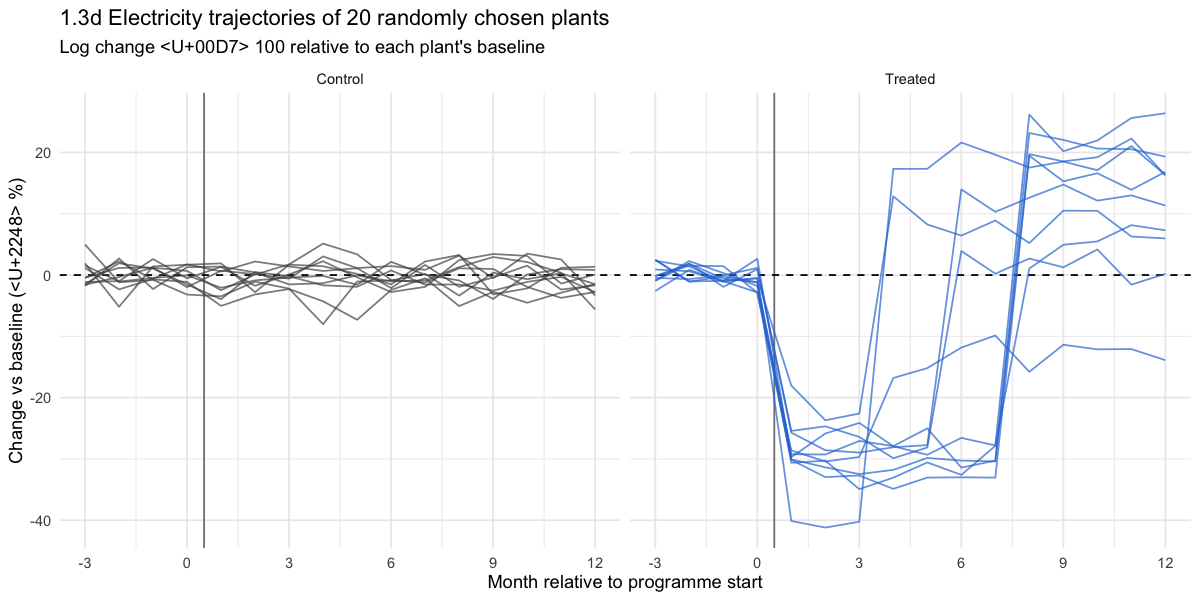

In [16]:
# Individual trajectories: 10 random plants per group
set.seed(123)
sample_ids <- plants |> group_by(group) |> slice_sample(n = 10) |> pull(firm_id)

energy |>
  filter(firm_id %in% sample_ids) |>
  ggplot(aes(x = month, y = 100 * dlog_E, group = firm_id, colour = group)) +
  geom_vline(xintercept = 0.5, colour = "grey50") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_line(alpha = 0.7) +
  facet_wrap(~group) +
  scale_colour_manual(values = group_colours, guide = "none") +
  scale_x_continuous(breaks = seq(-3, 12, 3)) +
  labs(title = "1.3d Electricity trajectories of 20 randomly chosen plants",
       subtitle = "Log change × 100 relative to each plant's baseline",
       x = "Month relative to programme start", y = "Change vs baseline (≈ %)") +
  theme_minimal()

# Part 2: Find the question, then develop an explanation

## 2. What does the time pattern tell you?

Look more closely at the evolution of electricity use. Does a single average for the period after consulting give an adequate account? Identify the features of the time path that would matter to a policymaker, and decide how to present them clearly.

Compare your conclusions across treated and control plants and consider whether the average hides differences across firms. State the main empirical pattern that your subsequent analysis needs to explain. Keep a description of that pattern separate from an explanation of why it occurs.

**TLDR of Section 2**

* **A single post-programme average is misleading.** Averaged over months 1–12, treated plants use about 7% less electricity. That number hides a 26% saving at first and a 9% *increase* later.
* **The rise happens in one step, exactly when labour becomes adjustable.** In each staffing-review cohort, treated plants' electricity jumps from about −26% to about +9% in the review month (4, 6 or 8) and then stays flat to month 12. The apparent "gradual erosion" in the pooled average is just the three cohorts switching at different dates.
* **Labour and output jump at the same moment**, by about +48% and +22%, and are flat before and after. Control plants do not change in any cohort.
* **The average hides large differences across plants.** The initial saving is similar across plants (about −26%), but the later change ranges from about −12% to +33%. It is larger in Chemicals and rises steadily with the share of electricity in a plant's variable costs.

### 2.1 Is a single post-programme average enough?

**Objective:** check whether one number for months 1–12 describes the programme's effect on electricity.

We can make the following observations:
* Over months 1–12 as a whole, treated plants use about 7% less electricity than at baseline; control plants do not change.
* This average combines three very different periods: −26% (months 1–3), −10% (months 4–7) and +9% (months 8–12). A policymaker told "−7%" would conclude the programme saves electricity, whereas by the end of the panel treated plants use *more* than before.
* The spread across plants is also very different by window: small in months 1–3, very large in months 4–7, intermediate in months 8–12. Section 2.2 shows why months 4–7 are so dispersed.

In [17]:
# Each plant's average log change vs its own baseline, for the whole post period and for each window
plant_post <- energy |>
  filter(month >= 1) |>
  group_by(firm_id, group) |>
  summarise(dlog_E = mean(dlog_E), .groups = "drop") |>
  mutate(period = "Months 1-12 (single average)")

plant_windows <- energy |>
  filter(month >= 1) |>
  group_by(firm_id, group, window) |>
  summarise(dlog_E = mean(dlog_E), .groups = "drop") |>
  transmute(firm_id, group, dlog_E, period = as.character(window))

bind_rows(plant_post, plant_windows) |>
  mutate(period = factor(period, levels = c("Months 1-12 (single average)",
                                            "Months 1-3", "Months 4-7", "Months 8-12"))) |>
  group_by(period, group) |>
  summarise(mean_change_pct = 100 * (exp(mean(dlog_E)) - 1),
            sd_across_plants = 100 * sd(dlog_E),
            .groups = "drop") |>
  pivot_wider(names_from = group, values_from = c(mean_change_pct, sd_across_plants)) |>
  mutate(across(where(is.double), \(x) round(x, 1)))

period,mean_change_pct_Control,mean_change_pct_Treated,sd_across_plants_Control,sd_across_plants_Treated
<fct>,<dbl>,<dbl>,<dbl>,<dbl>
Months 1-12 (single average),0.0,-6.9,1.1,7.8
Months 1-3,0.0,-26.0,1.5,6.4
Months 4-7,-0.1,-9.8,1.3,17.4
Months 8-12,0.0,9.4,1.3,9.0


### 2.2 Timing: electricity by staffing-review cohort

**Objective:** the pooled average in Section 1 rises in steps. Plants differ in when their paid labour can be adjusted (month 4, 6 or 8), so we split the time path by this cohort.

We can make the following observations:
* In all three cohorts, treated plants' electricity falls by about 26% in month 1 and stays at that level as long as labour is fixed.
* In each cohort, electricity jumps to about 9% above baseline **in the month labour becomes adjustable** (dotted line): month 4, 6 or 8. It does not move in the months just before.
* After the jump, electricity is flat through month 12. There is no further trend within the panel.
* Control plants are flat in every cohort.
* The gradual erosion seen in the pooled average is therefore a composition effect: one third of plants switch in month 4, another third in month 6, the last third in month 8.

adjust_month,Months 1-3,Months 4-7,Months 8-12
<dbl>,<dbl>,<dbl>,<dbl>
4,-26.4,9.5,9.3
6,-25.7,-9.7,9.7
8,-25.8,-25.8,9.3


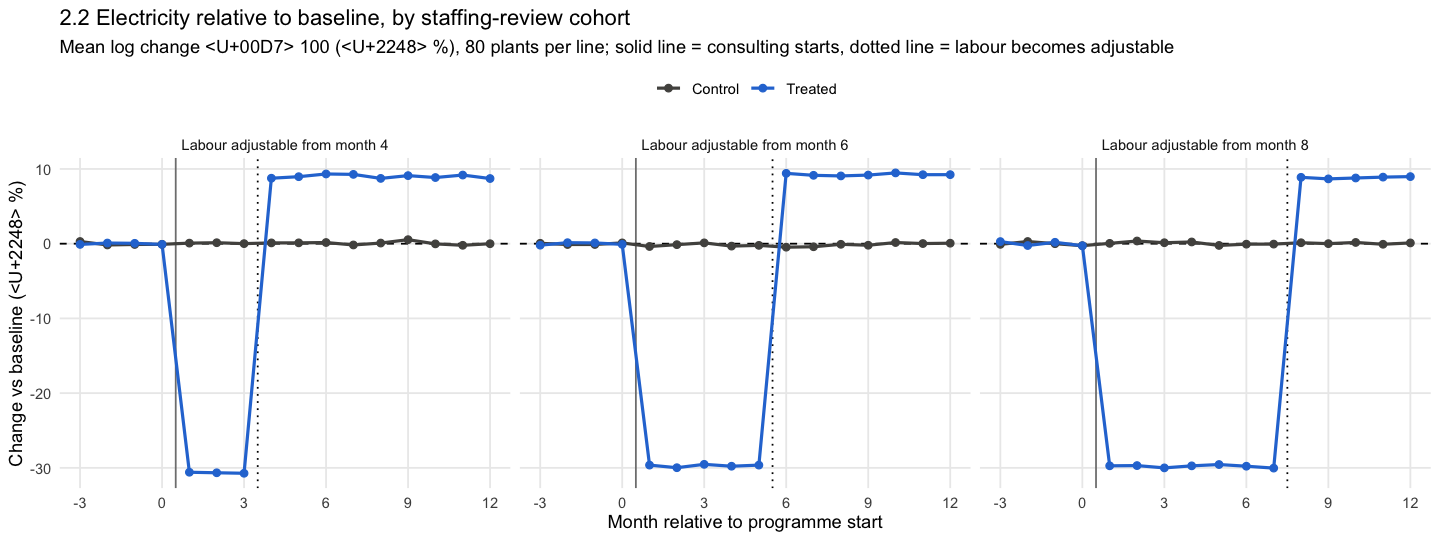

In [21]:
options(repr.plot.width = 12, repr.plot.height = 4.5)

energy |>
  group_by(adjust_month, month, group) |>
  summarise(mean = mean(dlog_E), .groups = "drop") |>
  mutate(cohort = paste("Labour adjustable from month", adjust_month)) |>
  ggplot(aes(x = month, y = 100 * mean, colour = group)) +
  geom_vline(xintercept = 0.5, colour = "grey50") +
  geom_vline(aes(xintercept = adjust_month - 0.5), linetype = "dotted") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_line(linewidth = 0.9) +
  geom_point(size = 1.8) +
  facet_wrap(~cohort, ncol = 3) +
  scale_colour_manual(values = group_colours, name = NULL) +
  scale_x_continuous(breaks = seq(-3, 12, 3)) +
  labs(title = "2.2 Electricity relative to baseline, by staffing-review cohort",
       subtitle = "Mean log change × 100 (≈ %), 80 plants per line; solid line = consulting starts, dotted line = labour becomes adjustable",
       x = "Month relative to programme start", y = "Change vs baseline (≈ %)") +
  theme_minimal() +
  theme(legend.position = "top", panel.grid.minor = element_blank())

options(repr.plot.width = 10, repr.plot.height = 5)

# Treated plants: mean change (%) by cohort and window
energy |>
  filter(treated == 1, month >= 1) |>
  group_by(adjust_month, window) |>
  summarise(mean_change_pct = round(100 * (exp(mean(dlog_E)) - 1), 1), .groups = "drop") |>
  pivot_wider(names_from = window, values_from = mean_change_pct)

### 2.3 Electricity, labour and output around the month labour becomes adjustable

**Objective:** align all plants on the month their labour becomes adjustable (event time 0) and look at the three quantities together. This is still a description of what moves and when, not an explanation.

We can make the following observations:
* **Before event time 0** (labour fixed): treated plants' electricity is about 26% below baseline, while their labour and output are unchanged.
* **At event time 0:** electricity, labour and output of treated plants all jump in the same month: electricity to about +9%, labour to about +48% and output to about +22% relative to baseline.
* **After event time 0:** all three stay flat. The change is a one-time jump, not a gradual adjustment.
* **Control plants** show no movement in any of the three quantities.

group,labour,plant_months,electricity_pct,labour_pct,output_pct
<fct>,<chr>,<int>,<dbl>,<dbl>,<dbl>
Control,Adjustable,1680,0.0,0.1,-0.1
Control,Fixed,1200,0.0,0.0,-0.1
Treated,Adjustable,1680,9.5,47.9,21.7
Treated,Fixed,1200,-25.9,0.0,0.0


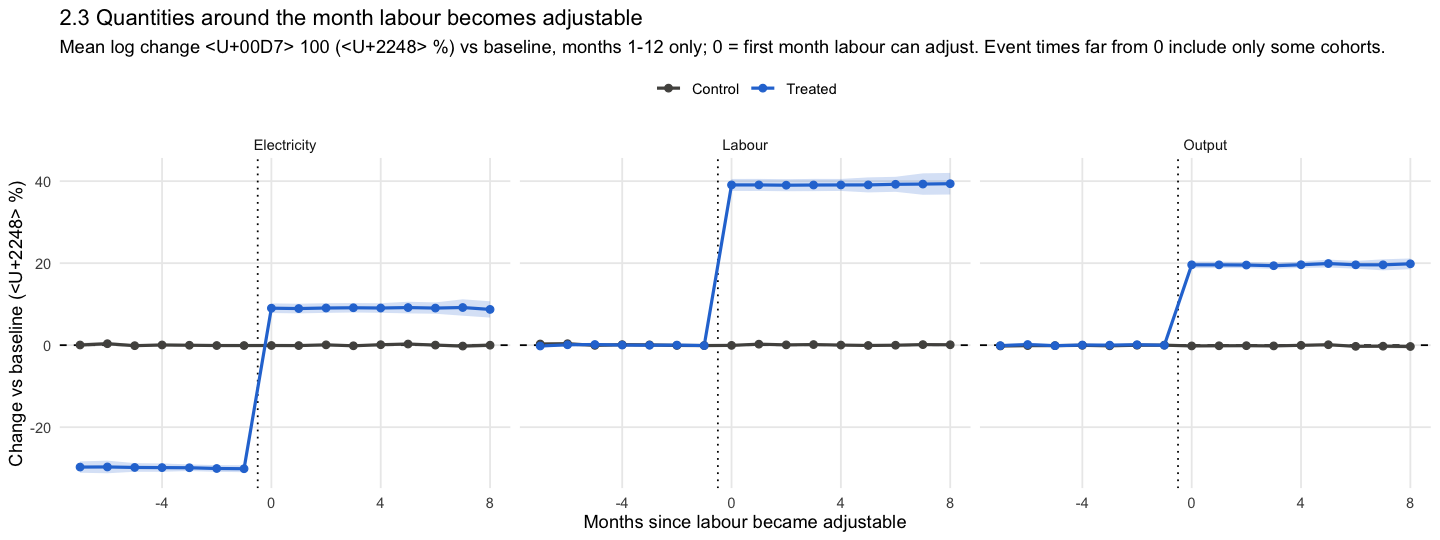

In [22]:
options(repr.plot.width = 12, repr.plot.height = 4.5)

energy |>
  filter(month >= 1) |>
  mutate(months_since_labour_adjustable = month - adjust_month) |>
  pivot_longer(c(dlog_E, dlog_L, dlog_Q), names_to = "variable", values_to = "change") |>
  mutate(variable = factor(recode(variable, dlog_E = "Electricity", dlog_L = "Labour", dlog_Q = "Output"),
                           levels = c("Electricity", "Labour", "Output"))) |>
  group_by(months_since_labour_adjustable, group, variable) |>
  summarise(mean = mean(change), se = sd(change) / sqrt(n()), .groups = "drop") |>
  ggplot(aes(x = months_since_labour_adjustable, y = 100 * mean, colour = group)) +
  geom_vline(xintercept = -0.5, linetype = "dotted") +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_ribbon(aes(ymin = 100 * (mean - 1.96 * se), ymax = 100 * (mean + 1.96 * se), fill = group),
              alpha = 0.2, colour = NA) +
  geom_line(linewidth = 0.9) +
  geom_point(size = 1.8) +
  facet_wrap(~variable) +
  scale_colour_manual(values = group_colours, name = NULL) +
  scale_fill_manual(values = group_colours, guide = "none") +
  labs(title = "2.3 Quantities around the month labour becomes adjustable",
       subtitle = "Mean log change × 100 (≈ %) vs baseline, months 1-12 only; 0 = first month labour can adjust. Event times far from 0 include only some cohorts.",
       x = "Months since labour became adjustable", y = "Change vs baseline (≈ %)") +
  theme_minimal() +
  theme(legend.position = "top", panel.grid.minor = element_blank())

options(repr.plot.width = 10, repr.plot.height = 5)

# Mean change (%) while labour is fixed and once it is adjustable (months 1-12)
energy |>
  filter(month >= 1) |>
  mutate(labour = if_else(labor_adjustable == 1, "Adjustable", "Fixed")) |>
  group_by(group, labour) |>
  summarise(plant_months = n(),
            electricity_pct = 100 * (exp(mean(dlog_E)) - 1),
            labour_pct = 100 * (exp(mean(dlog_L)) - 1),
            output_pct = 100 * (exp(mean(dlog_Q)) - 1),
            .groups = "drop") |>
  mutate(across(where(is.double), \(x) round(x, 1)))

### 2.4 Does the average hide differences across plants?

**Objective:** compare each treated plant's initial change (months 1–3) with its later change (months 8–12, when all cohorts can adjust labour), and see which plants change most. We describe these differences here and return to them in Question 6(c).

We can make the following observations:
* **The initial saving is fairly similar across plants:** in months 1–3 half of the treated plants are between about −29% and −23% (mean −26%; full range about −38% to −16%).
* **The later change varies much more:** from about −12% to +33% in months 8–12. Most treated plants (83%) end above their baseline, but about one in six is still below it.
* **The initial and later changes are almost unrelated** across plants (correlation ≈ −0.1): knowing how much a plant saved at first says little about how much it rebounds.
* **Sector.** The later increase is larger in Chemicals (+12%, 89% of plants above baseline) than in Textiles (+7%, 78%).
* **Electricity cost share.** The later change rises steadily with the share of electricity in a plant's variable costs at baseline: about −2.5% for the quarter of plants where electricity matters least, and +6.5%, +13.5% and +21.5% for the next quarters. The initial saving is about the same in all four groups. Since Chemicals plants have higher cost shares on average, part of the sector difference may reflect this.

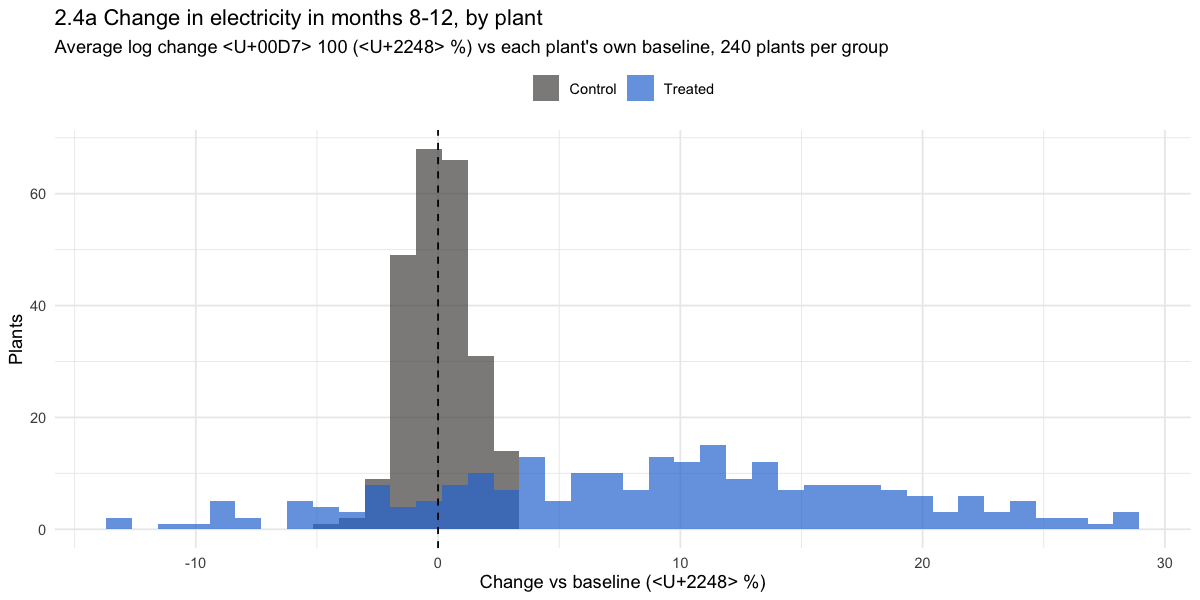

correlation_initial_later
<dbl>
-0.13


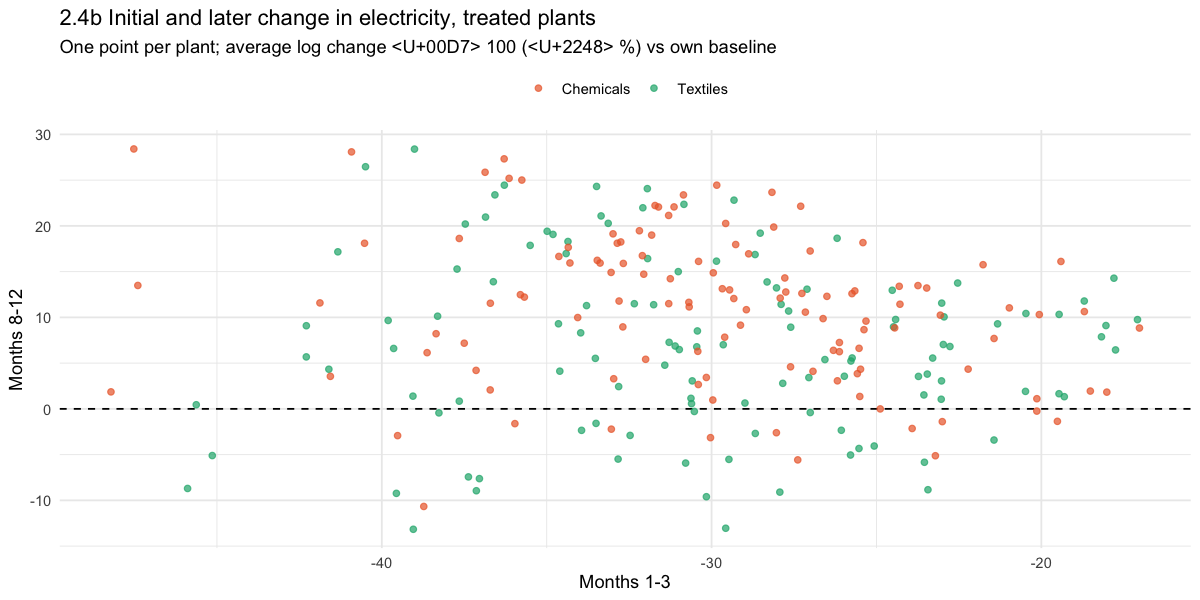

In [23]:
# Each plant's initial (months 1-3) and later (months 8-12) change vs its own baseline
plant_changes <- energy |>
  group_by(firm_id) |>
  summarise(initial = mean(dlog_E[month %in% 1:3]),
            later   = mean(dlog_E[month >= 8])) |>
  left_join(plants, by = "firm_id")

# Distribution of later changes
plant_changes |>
  ggplot(aes(x = 100 * later, fill = group)) +
  geom_histogram(bins = 40, alpha = 0.7, position = "identity") +
  geom_vline(xintercept = 0, linetype = "dashed") +
  scale_fill_manual(values = group_colours, name = NULL) +
  labs(title = "2.4a Change in electricity in months 8-12, by plant",
       subtitle = "Average log change × 100 (≈ %) vs each plant's own baseline, 240 plants per group",
       x = "Change vs baseline (≈ %)", y = "Plants") +
  theme_minimal() +
  theme(legend.position = "top")

# Initial vs later change, treated plants
plant_changes |>
  filter(treated == 1) |>
  ggplot(aes(x = 100 * initial, y = 100 * later, colour = sector)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_point(alpha = 0.7) +
  scale_colour_manual(values = sector_colours, name = NULL) +
  labs(title = "2.4b Initial and later change in electricity, treated plants",
       subtitle = "One point per plant; average log change × 100 (≈ %) vs own baseline",
       x = "Months 1-3", y = "Months 8-12") +
  theme_minimal() +
  theme(legend.position = "top")

plant_changes |>
  filter(treated == 1) |>
  summarise(correlation_initial_later = round(cor(initial, later), 2))

sector,plants,mean_cost_share,initial_change_pct,later_change_pct,share_above_baseline_later
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Chemicals,120,0.71,-25.85,11.60,0.89
Textiles,120,0.65,-26.07,7.28,0.78


cost_share_quartile,plants,mean_cost_share,initial_change_pct,later_change_pct,share_above_baseline_later
<chr>,<int>,<dbl>,<dbl>,<dbl>,<dbl>
Q1,60,0.50,-26.15,-2.49,0.33
Q2,60,0.65,-26.10,6.48,1.00
Q3,60,0.75,-25.14,13.55,1.00
Q4,60,0.84,-26.46,21.58,1.00


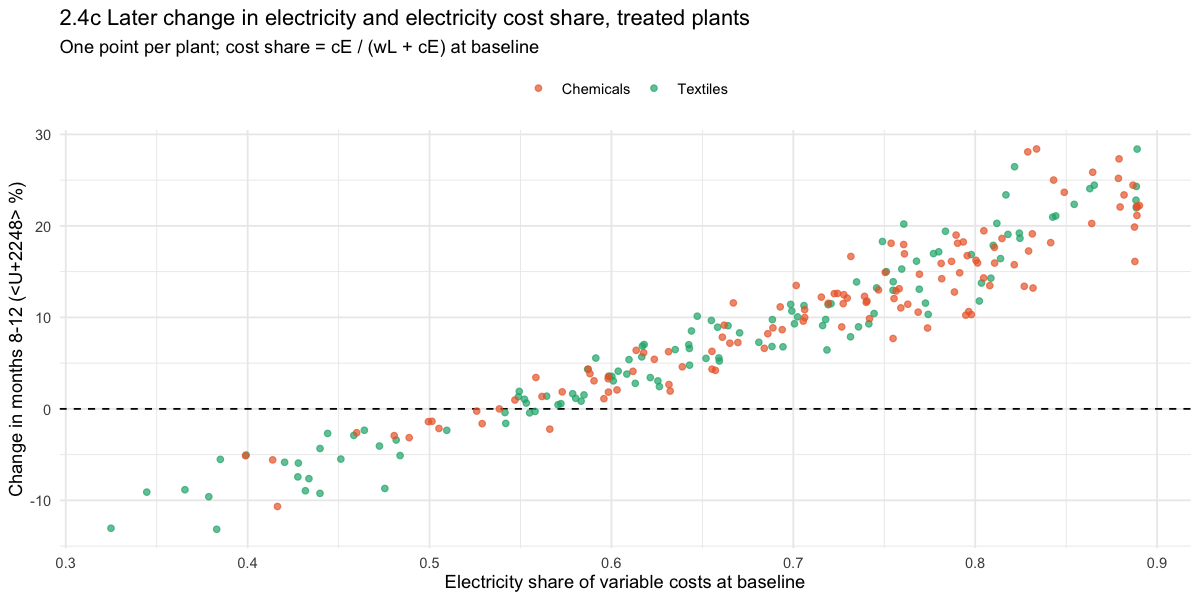

In [24]:
# Treated plants: initial and later change by sector and by quartile of electricity cost share
summarise_changes <- function(data) {
  data |>
    summarise(plants = n(),
              mean_cost_share = mean(energy_cost_share),
              initial_change_pct = 100 * (exp(mean(initial)) - 1),
              later_change_pct = 100 * (exp(mean(later)) - 1),
              share_above_baseline_later = mean(later > 0),
              .groups = "drop") |>
    mutate(across(where(is.double), \(x) round(x, 2)))
}

treated_changes <- plant_changes |>
  filter(treated == 1) |>
  mutate(cost_share_quartile = paste0("Q", ntile(energy_cost_share, 4)))

treated_changes |> group_by(sector) |> summarise_changes()
treated_changes |> group_by(cost_share_quartile) |> summarise_changes()

treated_changes |>
  ggplot(aes(x = energy_cost_share, y = 100 * later, colour = sector)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_point(alpha = 0.7) +
  scale_colour_manual(values = sector_colours, name = NULL) +
  labs(title = "2.4c Later change in electricity and electricity cost share, treated plants",
       subtitle = "One point per plant; cost share = cE / (wL + cE) at baseline",
       x = "Electricity share of variable costs at baseline", y = "Change in months 8-12 (≈ %)") +
  theme_minimal() +
  theme(legend.position = "top")

### 2.5 The main empirical pattern to explain

*This is a description of what the data shows in the analysis made*

> Consulting reduces treated plants' electricity use by about 26% immediately, with labour and output unchanged. This saving lasts only as long as each plant's paid labour is fixed. In the month a plant's labour becomes adjustable (4, 6 or 8), its electricity, labour and output all rise in a single step, to about +9%, +48% and +22% relative to baseline, and then stay at that level until month 12. Control plants do not change at any point. The initial saving is similar across plants, but the size of the later increase varies widely and is larger where electricity is a larger share of variable costs.

**Features that matter to a policymaker:**
1. **Horizon:** the programme saves electricity in the short run and increases it in the medium run. Any assessment depends on which horizon is used.
2. **Timing:** the switch is tied to when labour can be adjusted, not to time since consulting.
3. **Persistence:** after the switch the new level is stable within the panel, so the medium-run increase does not appear to be temporary.
4. **Other outcomes:** electricity is not the only thing that changes; output and employment rise substantially once labour adjusts.
5. **Heterogeneity:** the average medium-run effect hides plants that keep saving and plants that increase their use by 20–30%.

## 3. Evaluate the programme

Use the random assignment to assess whether consulting achieved its stated objective. Explain your comparison, your choice of outcome and time windows, and why the comparison is informative about the programme rather than simply about differences across plants or changes over time.

Report the size and uncertainty of the effects you consider relevant. Treat plants, rather than their repeated monthly observations, as the independent assignment units. Does the policy assessment depend on the horizon? Be precise about the difference between an average plant’s proportional response and the change in total electricity consumption.

**TLDR of Section 3**

* **Averaged over all consulting months, consulting reduces electricity by about 7%** relative to control plants. This average hides opposite effects at different horizons.
* **The assessment depends on the horizon.** Consulting cuts electricity by 26% at the start (months 1–3) and by about 10% in the middle (months 4–7), but *raises* it by about 9% at the end (months 8–12). All three effects are precisely estimated and different from zero.
* **Total consumption tells the same story.** Total electricity of treated plants is 26 percentage points lower than control at the start and about 10 points *higher* at the end, around 107,000 MWh a month more than without consulting. The average-plant and total measures differ slightly in months 4–12, because plants of different sizes respond differently.
* **Labour and output do not change at the start, but rise strongly later** (about +48% and +22% at the end). Prices do not change at all.
* **Conclusion:** the programme achieves its objective only in the short run. By the end of the panel, treated plants use more electricity than they would have without consulting.

### 3.1 The comparison

**Outcome.** The programme's objective is to reduce electricity consumption, so the main outcome is electricity use (MWh per month). We measure it in two ways, because they answer different questions:
* **The average plant's proportional change:** each plant's log change relative to its own baseline, averaged across plants. Every plant counts equally.
* **The change in total consumption:** the sum of MWh over all plants in a group. Large plants count more. This is what matters for aggregate electricity demand.

We also report labour and output, which help interpret the electricity results, and check that prices did not change.

**Comparison.** For each plant, we compare its average in each period with its own pre-programme average (months −3 to 0), and then compare this change between treated and control plants (difference in differences):

$$\text{Effect} = (\text{change of treated plants}) - (\text{change of control plants})$$

**Why it measures the programme.**
* *Not changes over time:* consulting was randomly assigned, so control plants show what treated plants would have done without consulting. Anything that affects all plants over time (seasonality, common shocks) cancels out. In fact, control plants do not change at all.
* *Not differences across plants:* each plant is compared with itself, which removes permanent differences in size and productivity, including the small baseline imbalance found in Section 1.

**Time windows.** We report the average over all consulting months (months 1–12) and three periods:
* **Start (months 1–3):** labour is fixed for every plant.
* **Middle (months 4–7):** a transition period that mixes plants that can already adjust labour (review in month 4 or 6) with plants that cannot yet (month 8).
* **End (months 8–12):** labour can be adjusted in every plant.

**Uncertainty.** Plants, not months, are the independent assignment units. We first average the months of each period within each plant, so each plant counts once (240 treated, 240 control), and compute 95% intervals and p-values across plants. Averaging months also reduces recording noise. For total consumption, we compute intervals by resampling plants (bootstrap).

In [25]:
# 3.1 Plant-level change by period, for electricity, labour and output

periods <- list(
  "Months 1-12 (all consulting months)" = 1:12,
  "Start (months 1-3)"                  = 1:3,
  "Middle (months 4-7)"                 = 4:7,
  "End (months 8-12)"                   = 8:12
)

# Long format: one row per plant, month and variable, with the plant's own baseline
energy_long <- energy |>
  select(firm_id, group, treated, month, electricity, labor, output,
         electricity_base, labor_base, output_base) |>
  pivot_longer(c(electricity, labor, output), names_to = "variable", values_to = "value") |>
  mutate(
    base = case_when(variable == "electricity" ~ electricity_base,
                     variable == "labor"       ~ labor_base,
                     variable == "output"      ~ output_base),
    dlog = log(value / base)
  )

# One observation per plant, variable and period: the plant is the unit of analysis
plant_period <- imap_dfr(periods, \(months, label)
  energy_long |>
    filter(month %in% months) |>
    group_by(firm_id, group, treated, variable) |>
    summarise(dlog = mean(dlog), value = mean(value), base = first(base), .groups = "drop") |>
    mutate(period = label)
) |>
  mutate(period = factor(period, levels = names(periods)))

plant_period |> count(variable, period, group) |> pivot_wider(names_from = group, values_from = n)

variable,period,Control,Treated
<chr>,<fct>,<int>,<int>
electricity,Months 1-12 (all consulting months),240,240
electricity,Start (months 1-3),240,240
electricity,Middle (months 4-7),240,240
electricity,End (months 8-12),240,240
labor,Months 1-12 (all consulting months),240,240
labor,Start (months 1-3),240,240
labor,Middle (months 4-7),240,240
labor,End (months 8-12),240,240
output,Months 1-12 (all consulting months),240,240


### 3.2 Effect on electricity: the average plant

We can make the following observations:
* **All consulting months together:** treated plants' electricity falls by about 7% relative to control (95% interval about −8% to −6%). Taken alone, this suggests a modest saving.
* **Start (months 1–3):** a large and very precise saving of 26% (−26.6% to −25.4%).
* **Middle (months 4–7):** the saving shrinks to about 10% (−12% to −8%).
* **End (months 8–12):** the effect reverses. Treated plants use about 9% **more** electricity than they would have without consulting (+8% to +11%).
* **Control plants** change by less than 0.1% in every period.
* The effects at the start and at the end are both clearly different from zero (p < 0.001) and have opposite signs. **The policy assessment depends on the horizon.**

In [26]:
# 3.2 Difference in differences by period, one observation per plant.
# Welch t-test across plants; percentages are exp(log change) - 1.

did_table <- plant_period |>
  group_by(variable, period) |>
  summarise(
    plants       = n(),
    treated_dlog = mean(dlog[treated == 1]),
    control_dlog = mean(dlog[treated == 0]),
    effect       = treated_dlog - control_dlog,
    se           = sqrt(var(dlog[treated == 1]) / sum(treated == 1) +
                        var(dlog[treated == 0]) / sum(treated == 0)),
    p_value      = t.test(dlog[treated == 1], dlog[treated == 0])$p.value,
    .groups = "drop"
  ) |>
  mutate(
    treated_change_pct = 100 * (exp(treated_dlog) - 1),
    control_change_pct = 100 * (exp(control_dlog) - 1),
    effect_pct         = 100 * (exp(effect) - 1),
    ci_low_pct         = 100 * (exp(effect - 1.96 * se) - 1),
    ci_high_pct        = 100 * (exp(effect + 1.96 * se) - 1),
    p_value            = format.pval(p_value, digits = 2, eps = 0.001)
  ) |>
  select(variable, period, plants, treated_change_pct, control_change_pct,
         effect_pct, ci_low_pct, ci_high_pct, p_value) |>
  mutate(across(where(is.double), \(x) round(x, 1)))

did_table |> filter(variable == "electricity")

variable,period,plants,treated_change_pct,control_change_pct,effect_pct,ci_low_pct,ci_high_pct,p_value
<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
electricity,Months 1-12 (all consulting months),480,-6.9,0.0,-6.9,-7.9,-6.0,<0.001
electricity,Start (months 1-3),480,-26.0,0.0,-26.0,-26.6,-25.4,<0.001
electricity,Middle (months 4-7),480,-9.8,-0.1,-9.7,-11.7,-7.7,<0.001
electricity,End (months 8-12),480,9.4,0.0,9.4,8.1,10.6,<0.001


### 3.3 Effect on electricity: total consumption

The average-plant effect weights every plant equally. Total consumption weights plants by size, and is what matters for aggregate electricity demand.

We can make the following observations:
* **Start (months 1–3):** total electricity of treated plants is 26 percentage points lower than control, about 275,000 MWh a month less than without consulting. Here the two measures coincide, because all plants cut by a similar proportion.
* **Middle (months 4–7):** the total falls by about 7 points, a smaller saving than for the average plant (−10%).
* **End (months 8–12):** total electricity is about 10 points **higher** than control, about 107,000 MWh a month more than without consulting. This is a slightly larger increase than for the average plant (+9%).
* **All consulting months:** about −5 points in total, against −7% for the average plant.
* The gap between the two measures is small: in months 8–12, plants with higher baseline electricity use increase it slightly more in proportion (about +10% in the largest quarter vs +8.5% in the smallest), so the total rises a little more than the average plant suggests. Section 2.4 showed that the later response varies across plants; Question 6(c) returns to which plants respond most.

In [27]:
# 3.3 Change in TOTAL electricity (MWh), treated vs control.
# effect_pp: (treated total change) - (control total change), in percentage points.
# effect_MWh_per_month: treated total minus what treated plants would have used had they
# changed like the controls. 95% intervals: bootstrap resampling plants (1,000 draws).

total_effect <- function(d) {
  t <- d[d$treated == 1, ]
  c <- d[d$treated == 0, ]
  sum(t$value) / sum(t$base) - sum(c$value) / sum(c$base)
}

set.seed(2026)
electricity_period <- plant_period |> filter(variable == "electricity")

total_table <- map_dfr(names(periods), function(p) {
  d <- electricity_period |> filter(period == p)
  t <- d[d$treated == 1, ]
  c <- d[d$treated == 0, ]
  boots <- replicate(1000, {
    i_t <- sample(which(d$treated == 1), replace = TRUE)
    i_c <- sample(which(d$treated == 0), replace = TRUE)
    total_effect(d[c(i_t, i_c), ])
  })
  tibble(
    period                   = p,
    treated_total_change_pct = 100 * (sum(t$value) / sum(t$base) - 1),
    control_total_change_pct = 100 * (sum(c$value) / sum(c$base) - 1),
    effect_pp                = 100 * total_effect(d),
    ci_low_pp                = 100 * unname(quantile(boots, 0.025)),
    ci_high_pp               = 100 * unname(quantile(boots, 0.975)),
    effect_MWh_per_month     = sum(t$value) - sum(t$base) * sum(c$value) / sum(c$base)
  )
}) |>
  mutate(across(where(is.double), \(x) round(x, 1)))

total_table

# Average plant vs total, side by side
did_table |>
  filter(variable == "electricity") |>
  select(period, average_plant_effect_pct = effect_pct) |>
  left_join(total_table |>
              mutate(period = factor(period, levels = names(periods))) |>
              select(period, total_effect_pp = effect_pp, effect_MWh_per_month),
            by = "period")

period,treated_total_change_pct,control_total_change_pct,effect_pp,ci_low_pp,ci_high_pp,effect_MWh_per_month
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
Months 1-12 (all consulting months),-4.7,0.0,-4.8,-5.9,-3.8,-50661.9
Start (months 1-3),-25.8,0.1,-26.0,-26.7,-25.3,-275224.7
Middle (months 4-7),-7.5,-0.1,-7.4,-9.7,-5.2,-78794.8
End (months 8-12),10.2,0.1,10.1,8.6,11.5,106582.1


period,average_plant_effect_pct,total_effect_pp,effect_MWh_per_month
<fct>,<dbl>,<dbl>,<dbl>
Months 1-12 (all consulting months),-6.9,-4.8,-50661.9
Start (months 1-3),-26.0,-26.0,-275224.7
Middle (months 4-7),-9.7,-7.4,-78794.8
End (months 8-12),9.4,10.1,106582.1


### 3.4 Labour, output and prices

**Objective:** check what else changes in the same periods. We report these as additional measured outcomes; Question 4 explains why they move as they do.

We can make the following observations:
* **Prices** (electricity price, wage, output price) do not change at all within any plant, so they cannot explain the changes over time.
* **Start (months 1–3):** labour and output of treated plants do not change (effects of about 0.1–0.2%, not significant). The 26% electricity saving happens with unchanged production.
* **Middle and end:** labour rises by about 22% and then 48%, and output by about 11% and then 22%, relative to control. Electricity rises over the same periods.
* **Control plants:** no change in labour or output in any period.

In [28]:
# 3.4a Labour and output: difference in differences by period
did_table |> filter(variable != "electricity")

# 3.4b Prices are fixed within each plant: largest change (max - min) within any plant, by group
energy |>
  group_by(firm_id, group) |>
  summarise(across(c(energy_price, wage, output_price), \(x) max(x) - min(x)), .groups = "drop") |>
  group_by(group) |>
  summarise(across(c(energy_price, wage, output_price), max))

variable,period,plants,treated_change_pct,control_change_pct,effect_pct,ci_low_pct,ci_high_pct,p_value
<chr>,<fct>,<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
labor,Months 1-12 (all consulting months),480,25.6,0.1,25.6,24.1,27.0,<0.001
labor,Start (months 1-3),480,0.0,0.1,-0.1,-0.3,0.1,0.28
labor,Middle (months 4-7),480,21.7,0.0,21.7,19.0,24.5,<0.001
labor,End (months 8-12),480,47.8,0.1,47.6,45.5,49.8,<0.001
output,Months 1-12 (all consulting months),480,12.1,-0.1,12.2,11.6,12.9,<0.001
output,Start (months 1-3),480,0.0,-0.1,0.2,-0.1,0.4,0.20
output,Middle (months 4-7),480,10.4,-0.1,10.5,9.2,11.7,<0.001
output,End (months 8-12),480,21.6,-0.1,21.7,20.8,22.7,<0.001


group,energy_price,wage,output_price
<fct>,<dbl>,<dbl>,<dbl>
Control,0,0,0
Treated,0,0,0


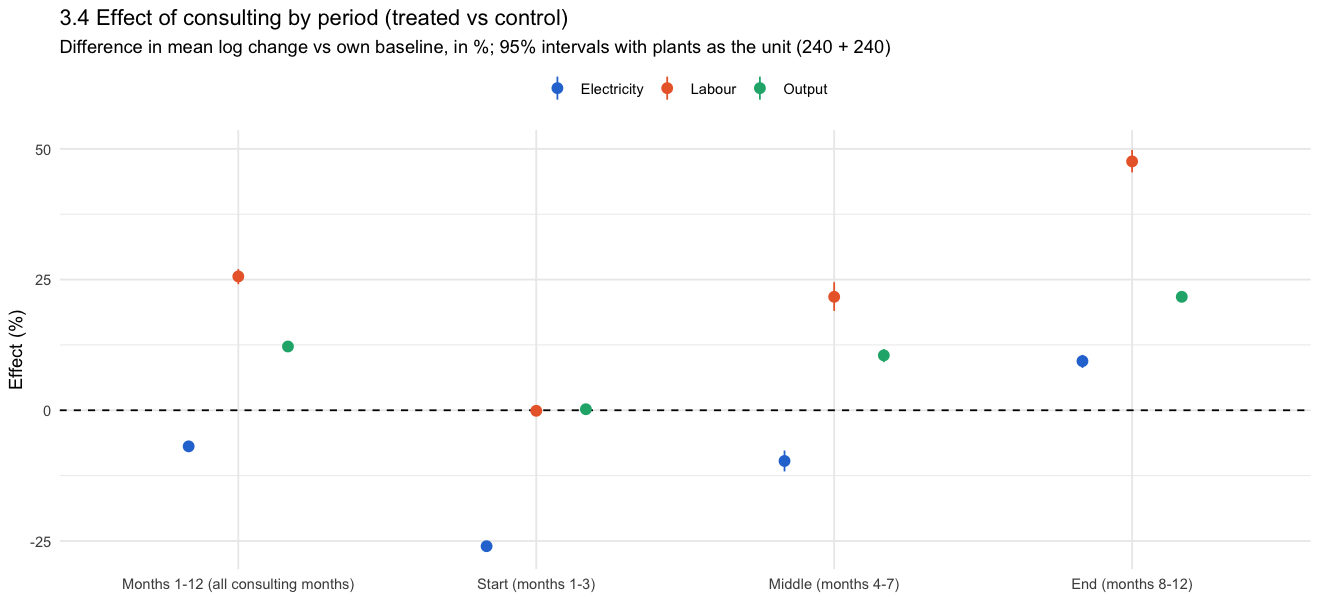

In [29]:
# 3.4c Effects on electricity, labour and output by period, with 95% intervals
options(repr.plot.width = 11, repr.plot.height = 5)

did_table |>
  mutate(variable = recode(variable, electricity = "Electricity", labor = "Labour", output = "Output")) |>
  ggplot(aes(x = period, y = effect_pct, colour = variable)) +
  geom_hline(yintercept = 0, linetype = "dashed") +
  geom_pointrange(aes(ymin = ci_low_pct, ymax = ci_high_pct),
                  position = position_dodge(width = 0.5)) +
  scale_colour_manual(values = c(Electricity = "#2a78d6", Labour = "#eb6834", Output = "#1baf7a"),
                      name = NULL) +
  labs(title = "3.4 Effect of consulting by period (treated vs control)",
       subtitle = "Difference in mean log change vs own baseline, in %; 95% intervals with plants as the unit (240 + 240)",
       x = NULL, y = "Effect (%)") +
  theme_minimal() +
  theme(legend.position = "top")

options(repr.plot.width = 10, repr.plot.height = 5)

### 3.5 Assessment

* **Did consulting achieve its objective?** Only in the short run. While labour is fixed, consulting cuts electricity by about 26%, for the average plant and in total. Once plants can adjust labour, the effect reverses: by months 8–12 treated plants use about 9% more electricity (average plant) and about 10% more in total, roughly 107,000 MWh a month, than they would have without consulting.
* **Does the assessment depend on the horizon?** Yes, completely. A single average over months 1–12 (about −7%) would wrongly suggest a lasting saving. The relevant horizon for policy is the end of the panel, when all plants have adjusted, and there the programme increases electricity use.
* **Average plant vs total:** the two measures agree on sign and rough size at every horizon. Total consumption rises slightly more than the average plant's use at the end, because larger electricity users increase their use slightly more in proportion.
* **What else changes:** the electricity increase comes with large increases in labour and output; prices do not change. Electricity savings are therefore not the only consequence of the programme, which matters for the policy discussion in Questions 7 and 8.

## 4. Use Unit 3 to make sense of the findings

q = Ai
p
min{L, ηE}.

Ai > 0 is persistent plant productivity; η > 0 measures the energy services obtained from physical electricity,

in units comparable with labor. Consulting aims to improve η. Neither its initial level nor its realised percent-
age change is supplied. Plants take their observed prices as given and seek to maximise operating profits,

pq − wL − cE.

In [ ]:
#*Answer:*  

# Part 3: Turn your explanation into further evidence

## 5. Can the initial response reveal the efficiency gain?

The programme assigns consulting, not a known percentage increase in efficiency. Using your explanation from Question 4, can you use the observations before the intervention and in months 1–3 to estimate the technological effect of consulting?

Explain which observed quantities you need and why. In particular, establish the conditions under which the initial electricity response is informative about efficiency, and check whether the accompanying observations support those conditions. Distinguish the level of η from its percentage change, and use the control plants to assess the change attributable to consulting. Allow for recording noise by combining observations where
appropriate.

Then investigate whether the efficiency change you infer appears to persist later. Explain how you would assess this once other input quantities can change. Be clear about which parts of the conclusion depend on the proposed technology.

In [ ]:
#*Answer:*  

## 6. Does your explanation predict more than the initial pattern?

A convincing mechanism should generate additional, testable implications. Derive predictions from your explanation and choose new tables, figures or comparisons to investigate each of the following.

    (a) The magnitude of later choices. Does profit maximisation predict plants’ later output and input quantities accurately? Use only baseline observations and months 1–3 to recover any required plant parameters. Make predictions before comparing them with the held-out observations in months 9–12. Examine discrepancies as well as fit.

    (b) Production and electricity. Is the observed change in production large enough to account for the later electricity response, given the efficiency change you estimated? Derive a quantitative criterion and identify which plants meet it. A matching sign alone is not sufficient.

    (c) Differences across firms. According to your mechanism, which pre-intervention characteristics should predict the strongest later electricity responses? Derive and investigate that prediction. Distinguish differences in the size of the efficiency improvement from differences in firms’ responses to a given improvement.

    (d) Input relationships and timing. What relationships between labor and electricity changes should your explanation imply? Do these differ when you compare later observations with baseline rather than with the initial post-intervention period? Investigate these relationships and whether the timing of responses is consistent with the institutional setting.

Explain what each piece of evidence establishes. Distinguish predictions tested against additional observations from identities built from the same quantities. Consider at least one alternative explanation, what would distinguish it from yours, and any limits of the available evidence.

In [ ]:
#*Answer:*  

# Part 4: Turn your explanation into further evidence

## 7. Evaluate a further efficiency improvement

Suppose a follow-up programme could raise each treated plant’s current η by a further 20%, with Ai and prices unchanged. This is additional to the original intervention; there are no observations from the proposed programme.
Predict output, labor, electricity and operating profits with labor first fixed at the current medium-run level, then freely adjustable. Compare both scenarios with the same no-follow-up baseline. Aggregate the results and examine differences across plants. Explain why extrapolating the original percentage effect might be misleading. Profits exclude the unknown cost of delivering consulting.

*Optional policy extension.* After the original intervention, what plant-specific electricity levy would keep medium-run electricity use at or below its pre-intervention level? Set the levy to zero where none is needed. Let plants reoptimise; report output, profits and tax revenue. Explain why this is not an estimate of an optimal environmental tax or necessarily a feasible uniform policy.

In [ ]:
#*Answer:*  

## 8. Brief the policymaker

Write a 200–300 word briefing assessing the original programme and the proposed follow-up. Explain the mechanism in plain language, ground your recommendation in evidence and uncertainty, and identify the most useful additional information or policy test.

Distinguish electricity savings from output, private profits and social welfare. Environmental damages and programme-delivery costs are not observed. There is no prescribed policy recommendation.

In [ ]:
#*Answer:*  

## 9. Optional: a short Cobb–Douglas comparison

Consider the alternative q = AiL 1/4 (ηE) 1/4. At unchanged input prices, derive its optimal labor-to-electricity ratio when both inputs can adjust. With labor fixed, determine the direction of the electricity response to improved efficiency. How do these predictions compare with the minimum model and the evidence?

This is a short comparison to clarify how technology affects behaviour. Do not recalibrate or simulate the alternative. Explain why rejecting it would not establish that the minimum technology is uniquely correct. This question is outside the core workload.

In [ ]:
#*Answer:*  